# Product KPIs, conversion funnels, and visitor segmentation

**Project source:** [Retailrocket recommender system dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset), `events.csv`.

This notebook defines product KPIs, measures drop-off, segments visitor behaviour, and tests
conversion associations. It reads the project's curated Delta tables; Spark computes the
large aggregations and only small summary tables are collected into Pandas.

**Execution provenance:** the committed example was executed on the project's **2,700,000
synthetic events**, not on downloaded Retailrocket data. Every result below displays its
configured source. Synthetic findings demonstrate the workflow and are not real business
insights. The default source for a fresh run is Retailrocket; missing real outputs cause a
clear error rather than silently substituting synthetic data.

## Questions and KPI definitions

1. Where do eligible sessions drop out of the product journey?
2. Which products contribute the largest absolute cart abandonment volumes?
3. How do first observed, returning, and product-breadth segments differ descriptively?
4. Is sampled-eligible-session conversion associated with weekend versus weekday timing?

| KPI | Numerator / denominator or definition | Unit |
| --- | --- | --- |
| Active visitors | Distinct anonymous `visitorid` values | Visitor |
| Any-purchase session rate | Sessions with any purchase event / all sessions | Session |
| Ordered funnel conversion | Sessions completing view → cart → purchase for the same product / sessions with a view | Session |
| View-to-cart rate | Sessions with a qualifying cart after a view / viewed sessions | Session |
| Cart-to-purchase rate | Ordered converted sessions / qualifying carted sessions | Session |
| Cart abandonment rate | 1 − cart-to-purchase rate | Session |
| Single-event session rate | Sessions containing one event / all sessions; a bounce proxy | Session |
| Returning visitor share | Visitors with at least two observed sessions / all visitors | Visitor |
| Product funnel conversion | Ordered converted session/product pairs / viewed session/product pairs | Session/product |

Sessions use the pipeline's 30-minute inactivity threshold and UTC dates. Ordered stages
allow equal timestamps and must concern the same product within a session. Purchases without
a qualifying preceding view/cart remain in any-purchase KPIs but do not count as ordered
conversions. A zero denominator produces an undefined rate, not 0%.

There are no device, campaign, demographic, usable order-price, or verified account fields
in this event input. We do not invent those segments or revenue KPIs. Returning means
returning **within the observed dataset**, which may miss earlier history.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyspark.sql import Window
from pyspark.sql import functions as F
from statsmodels.stats.multitest import multipletests

from ecommerce_analytics.inference import compare_conversion_groups, conversion_interval
from ecommerce_analytics.spark import local_spark

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "pyproject.toml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or its notebooks directory.")

DATA_SOURCE = os.environ.get("ECOMMERCE_DATA_SOURCE", "retailrocket")
if DATA_SOURCE not in {"retailrocket", "synthetic"}:
    raise ValueError("ECOMMERCE_DATA_SOURCE must be retailrocket or synthetic")
relative = "output/retailrocket" if DATA_SOURCE == "retailrocket" else "output/synthetic-2700000"
OUTPUT_ROOT = Path(os.environ.get("ECOMMERCE_OUTPUT_PATH", str(PROJECT_ROOT / relative))).resolve()
DATA_LABEL = "Retailrocket events" if DATA_SOURCE == "retailrocket" else "SYNTHETIC DEMONSTRATION"
if not (OUTPUT_ROOT / "gold" / "sessions" / "_delta_log").is_dir():
    raise FileNotFoundError(
        f"Missing curated outputs: {OUTPUT_ROOT}. Run the pipeline first; see README.md. "
        "For the synthetic example, set ECOMMERCE_DATA_SOURCE=synthetic explicitly."
    )

os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
pd.options.display.float_format = "{:,.4f}".format
plt.style.use("seaborn-v0_8-whitegrid")
display(Markdown(f"**Active input: {DATA_LABEL}** — `{OUTPUT_ROOT}`"))

**Active input: SYNTHETIC DEMONSTRATION** — `/workspace/Ecommerce-Customer-Behavior-Analytics/output/synthetic-2700000`

In [2]:
spark = local_spark("local[4]", 16)
sessions = spark.read.format("delta").load(str(OUTPUT_ROOT / "gold/sessions"))
journeys = spark.read.format("delta").load(str(OUTPUT_ROOT / "gold/session_products"))
products = spark.read.format("delta").load(str(OUTPUT_ROOT / "gold/product_metrics"))
daily = spark.read.format("delta").load(str(OUTPUT_ROOT / "gold/daily_funnel"))

stage_flags = journeys.groupBy("session_id").agg(
    F.max(F.col("first_view").isNotNull().cast("long")).alias("viewed"),
    F.max(F.col("first_cart_after_view").isNotNull().cast("long")).alias("carted"),
    F.max(F.col("first_purchase_after_cart").isNotNull().cast("long")).alias("converted"),
)
visit_order = Window.partitionBy("user_id").orderBy("session_start", "session_id")
analysis = (
    sessions.join(stage_flags, "session_id", "inner")
    .withColumn("observed_visit_number", F.row_number().over(visit_order))
    .withColumn(
        "visit_type",
        F.when(F.col("observed_visit_number") == 1, "first observed").otherwise(
            "returning observed"
        ),
    )
    .withColumn(
        "breadth",
        F.when(F.col("unique_products") == 1, "one product").otherwise("multiple products"),
    )
    .withColumn("weekday_index", (F.dayofweek("session_start") + 5) % 7)
    .persist()
)
assert analysis.count() == sessions.count(), "Stage join must preserve one row per session"
assert analysis.filter("converted > carted OR carted > viewed").count() == 0
summary = (
    analysis.agg(
        F.count("*").alias("sessions"),
        F.countDistinct("user_id").alias("visitors"),
        F.sum("event_count").alias("events"),
        F.sum("viewed").alias("viewed"),
        F.sum("carted").alias("carted"),
        F.sum("converted").alias("converted"),
        F.sum((F.col("purchases") > 0).cast("long")).alias("any_purchase_sessions"),
        F.sum((F.col("event_count") == 1).cast("long")).alias("single_event_sessions"),
        F.avg("event_count").alias("mean_events_per_session"),
        F.avg("duration_seconds").alias("mean_session_seconds"),
        F.percentile_approx("duration_seconds", 0.5).alias("median_session_seconds"),
    )
    .first()
    .asDict()
)
visitor_summary = (
    sessions.groupBy("user_id")
    .agg(F.count("*").alias("session_count"), F.sum("purchases").alias("purchases"))
    .agg(
        F.sum((F.col("session_count") >= 2).cast("long")).alias("returning_visitors"),
        F.sum((F.col("purchases") > 0).cast("long")).alias("purchasing_visitors"),
    )
    .first()
    .asDict()
)


def rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan


kpis = pd.DataFrame(
    [
        ("Active visitors", summary["visitors"]),
        ("Sessions", summary["sessions"]),
        ("Curated events", summary["events"]),
        ("Any-purchase session rate", rate(summary["any_purchase_sessions"], summary["sessions"])),
        ("Ordered funnel conversion", rate(summary["converted"], summary["viewed"])),
        ("View-to-cart rate", rate(summary["carted"], summary["viewed"])),
        ("Cart-to-purchase rate", rate(summary["converted"], summary["carted"])),
        ("Cart abandonment rate", 1 - rate(summary["converted"], summary["carted"])),
        ("Single-event session rate", rate(summary["single_event_sessions"], summary["sessions"])),
        (
            "Returning visitor share",
            rate(visitor_summary["returning_visitors"], summary["visitors"]),
        ),
        ("Mean events per session", summary["mean_events_per_session"]),
        ("Mean session duration (seconds)", summary["mean_session_seconds"]),
        ("Median session duration (seconds)", summary["median_session_seconds"]),
    ],
    columns=["KPI", "value"],
)
display(Markdown(f"### KPI scorecard — {DATA_LABEL}\nRates are fractions from 0 to 1."))
display(kpis)

https://repo.maven.apache.org/maven2 added as a remote repository with the name: repo-1


26/10/14 07:59:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/14 07:59:20 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


### KPI scorecard — SYNTHETIC DEMONSTRATION
Rates are fractions from 0 to 1.

,KPI,value
0,Active visitors,"100,000.0000"
1,Sessions,"1,810,659.0000"
2,Curated events,"2,700,000.0000"
3,Any-purchase session rate,0.1402
4,Ordered funnel conversion,0.1402
5,View-to-cart rate,0.3509
6,Cart-to-purchase rate,0.3996
7,Cart abandonment rate,0.6004
8,Single-event session rate,0.6491
9,Returning visitor share,1.0000


## Funnel loss and daily patterns

Absolute loss identifies volume; the fraction lost identifies efficiency. Both matter:
a small product with an extreme rate may contribute fewer lost journeys than a popular
product with a moderate rate. The daily series uses session start dates and is descriptive;
repeat visitors mean its session-level observations are not independent Bernoulli trials.

,transition,eligible_sessions,progressed_sessions,lost_sessions,dropoff_rate
0,View → cart,1810659,635447,1175212,0.6491
1,Cart → purchase,635447,253894,381553,0.6004


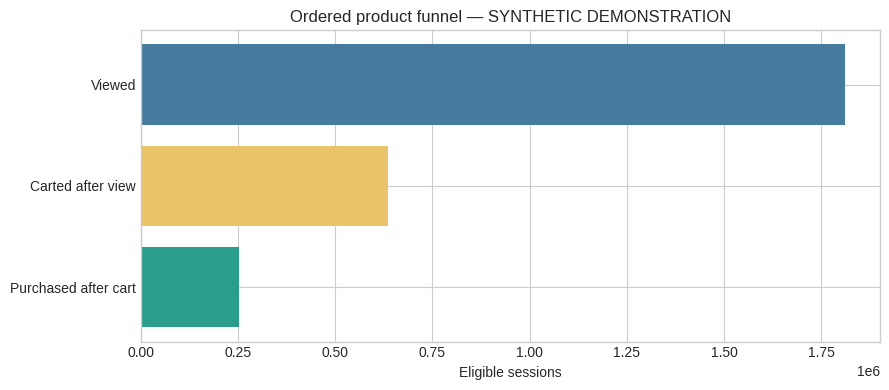

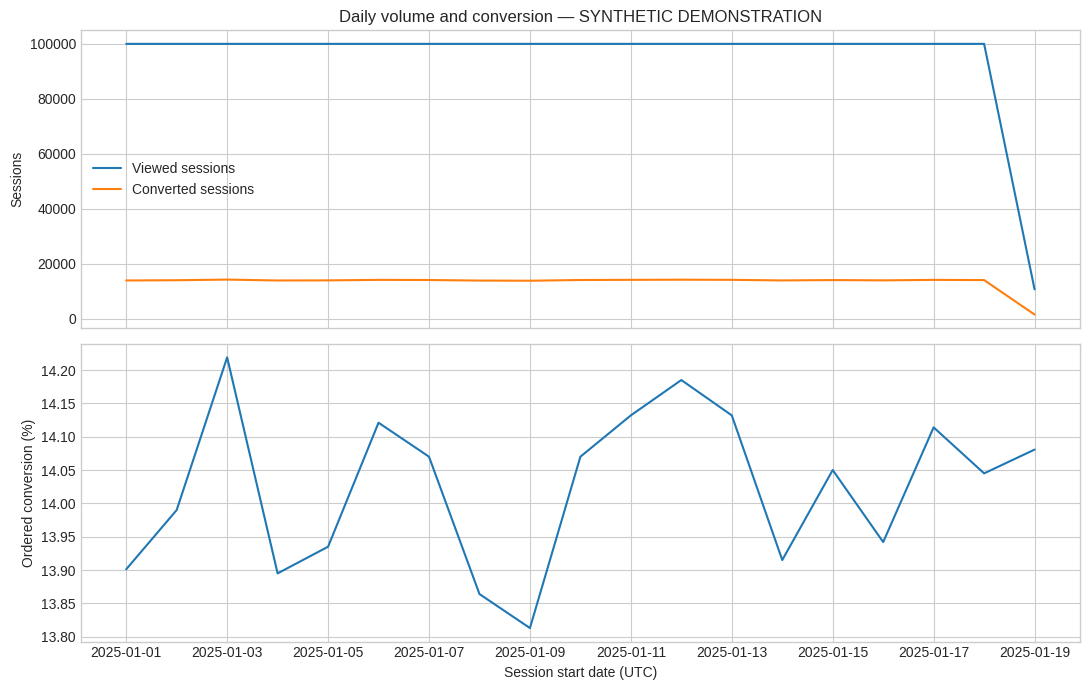

In [3]:
funnel = pd.DataFrame(
    {
        "stage": ["Viewed", "Carted after view", "Purchased after cart"],
        "sessions": [summary["viewed"], summary["carted"], summary["converted"]],
    }
)
dropoff = pd.DataFrame(
    [
        ("View → cart", summary["viewed"], summary["carted"]),
        ("Cart → purchase", summary["carted"], summary["converted"]),
    ],
    columns=["transition", "eligible_sessions", "progressed_sessions"],
)
dropoff["lost_sessions"] = dropoff.eligible_sessions - dropoff.progressed_sessions
dropoff["dropoff_rate"] = [
    rate(lost, total) for lost, total in zip(dropoff.lost_sessions, dropoff.eligible_sessions)
]
display(dropoff)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(funnel.stage[::-1], funnel.sessions[::-1], color=["#2a9d8f", "#e9c46a", "#457b9d"])
ax.set(xlabel="Eligible sessions", title=f"Ordered product funnel — {DATA_LABEL}")
plt.tight_layout()
plt.show()

daily_pd = daily.orderBy("session_date").toPandas()
daily_pd["session_date"] = pd.to_datetime(daily_pd.session_date)
for column in ["view_to_cart_rate", "cart_to_purchase_rate", "view_to_purchase_rate"]:
    daily_pd[column] = pd.to_numeric(daily_pd[column], errors="coerce")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(daily_pd.session_date, daily_pd.viewed_sessions, label="Viewed sessions")
axes[0].plot(daily_pd.session_date, daily_pd.purchased_sessions, label="Converted sessions")
axes[0].set(ylabel="Sessions", title=f"Daily volume and conversion — {DATA_LABEL}")
axes[0].legend()
axes[1].plot(daily_pd.session_date, daily_pd.view_to_purchase_rate * 100)
axes[1].set(xlabel="Session start date (UTC)", ylabel="Ordered conversion (%)")
plt.tight_layout()
plt.show()

### Largest product cart-loss volumes — SYNTHETIC DEMONSTRATION
At least 30 viewed session/product pairs; descriptive ranking.

,product_id,interacting_sessions,viewed_sessions,carted_sessions,converted_sessions,purchase_events,abandoned_sessions,conversion_rate
0,4698,392,392,162,53,53,109,0.1352
1,1914,427,427,165,58,58,107,0.1358
2,1571,392,392,150,44,44,106,0.1122
3,2068,368,368,158,53,53,105,0.1440
4,4824,362,362,149,44,44,105,0.1215
5,1475,362,362,150,46,46,104,0.1271
6,2107,389,389,144,40,40,104,0.1028
7,996,383,383,152,48,48,104,0.1253
8,2862,401,401,156,53,53,103,0.1322
9,3334,385,385,141,38,38,103,0.0987


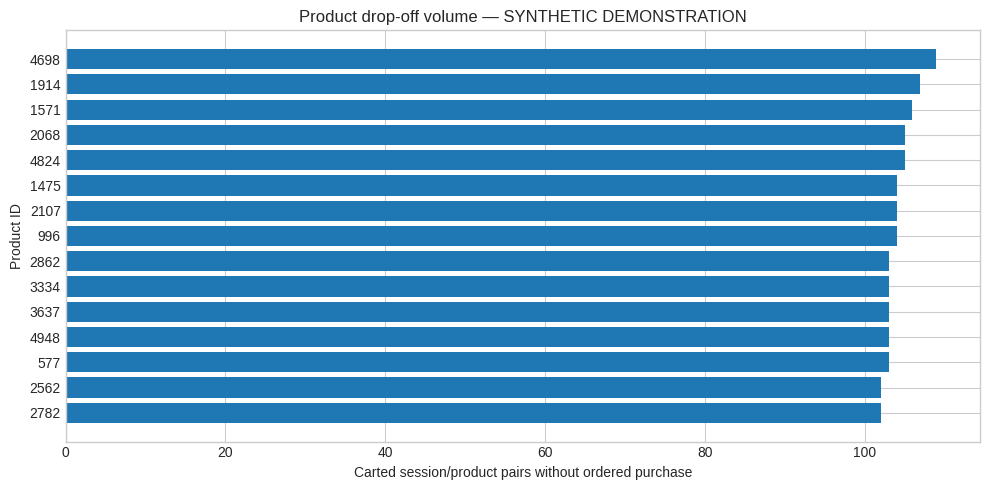

In [4]:
MIN_PRODUCT_VIEWS = 30
product_pd = (
    products.filter(F.col("viewed_sessions") >= MIN_PRODUCT_VIEWS)
    .withColumn("abandoned_sessions", F.col("carted_sessions") - F.col("converted_sessions"))
    .withColumn("conversion_rate", F.col("converted_sessions") / F.col("viewed_sessions"))
    .orderBy(F.desc("abandoned_sessions"), "product_id")
    .limit(15)
    .toPandas()
)
display(
    Markdown(
        f"### Largest product cart-loss volumes — {DATA_LABEL}\n"
        f"At least {MIN_PRODUCT_VIEWS} viewed session/product pairs; descriptive ranking."
    )
)
display(product_pd)
if not product_pd.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(product_pd.product_id.astype(str)[::-1], product_pd.abandoned_sessions[::-1])
    ax.set(
        xlabel="Carted session/product pairs without ordered purchase",
        ylabel="Product ID",
        title=f"Product drop-off volume — {DATA_LABEL}",
    )
    plt.tight_layout()
    plt.show()

## Behavioural segmentation

Segment sessions by first versus returning observation and by number of interacted products.
These segments are descriptive: product breadth is measured during the completed session,
so it can be affected by the same behaviour as purchase. Segment differences must not be
interpreted as treatment effects or evidence that increasing breadth causes conversion.
Returning status is also affected by the dataset observation window.

,visit_type,breadth,sessions,viewed_sessions,carted_sessions,converted_sessions,mean_events,conversion_rate,cart_abandonment_rate
0,first observed,one product,100000,100000,35230,13902,1.4913,0.1390,0.6054
1,returning observed,one product,1710659,1710659,600217,239992,1.4912,0.1403,0.6002


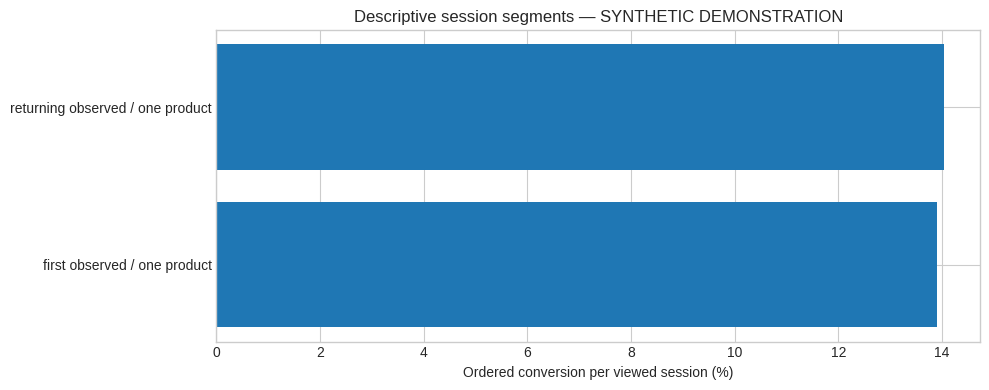

In [5]:
segments = (
    analysis.groupBy("visit_type", "breadth")
    .agg(
        F.count("*").alias("sessions"),
        F.sum("viewed").alias("viewed_sessions"),
        F.sum("carted").alias("carted_sessions"),
        F.sum("converted").alias("converted_sessions"),
        F.avg("event_count").alias("mean_events"),
    )
    .orderBy("visit_type", "breadth")
    .toPandas()
)
segments["conversion_rate"] = [
    rate(converted, viewed)
    for converted, viewed in zip(segments.converted_sessions, segments.viewed_sessions)
]
segments["cart_abandonment_rate"] = [
    1 - rate(converted, carted)
    for converted, carted in zip(segments.converted_sessions, segments.carted_sessions)
]
display(segments)
fig, ax = plt.subplots(figsize=(10, 4))
labels = segments.visit_type + " / " + segments.breadth
ax.barh(labels, segments.conversion_rate * 100)
ax.set(
    xlabel="Ordered conversion per viewed session (%)",
    title=f"Descriptive session segments — {DATA_LABEL}",
)
plt.tight_layout()
plt.show()

## Statistical unit, uncertainty, and hypotheses

For inference, take **one eligible viewed session per visitor**, selected by a fixed hash of session ID and seed 42, without looking at conversion outcomes. The binary outcome
is ordered funnel conversion within that session. This prevents repeatedly counting a
visitor's sessions as independent units. Anonymous IDs can still represent shared visitors
or multiple identities, so independence remains an assumption, not a guarantee.

**Primary hypothesis**, specified here before inspecting the comparison: H₀ is equal conversion
probability for sampled eligible sessions starting on weekends and weekdays; H₁ is a difference
in either direction. Use a two-sided test at α = 0.05. Timing is observational, not randomized:
calendar effects, visitor mix, product mix, and truncation of the dataset can confound it.

Report Wilson 95% intervals for each proportion and a Newcombe-Wilson interval for the
absolute difference (weekend minus weekday). Use Pearson's chi-square test only when all
expected cells are at least 5; otherwise use Fisher's exact test. If a group is empty,
report the test as unrun. The difference interval is descriptive and not multiplicity-adjusted.

**Exploratory family:** six day-of-week comparisons against Monday, using the same visitor
unit. Apply Holm correction across all six planned comparisons; missing groups are unrun
and contribute p = 1 to the correction, while their displayed p-values remain undefined.
These reuse the primary population and are follow-up exploration, not independent confirmation.

### Sampled-eligible-session visitor cohort — SYNTHETIC DEMONSTRATION

,day,visitors,converted_visitors,conversion_rate,ci_low,ci_high
0,Monday,10969,1477,0.1347,0.1284,0.1412
1,Tuesday,10967,1518,0.1384,0.1321,0.1450
2,Wednesday,16651,2344,0.1408,0.1356,0.1461
3,Thursday,16573,2262,0.1365,0.1313,0.1418
4,Friday,16620,2370,0.1426,0.1374,0.1480
5,Saturday,16522,2271,0.1375,0.1323,0.1428
6,Sunday,11698,1662,0.1421,0.1359,0.1485


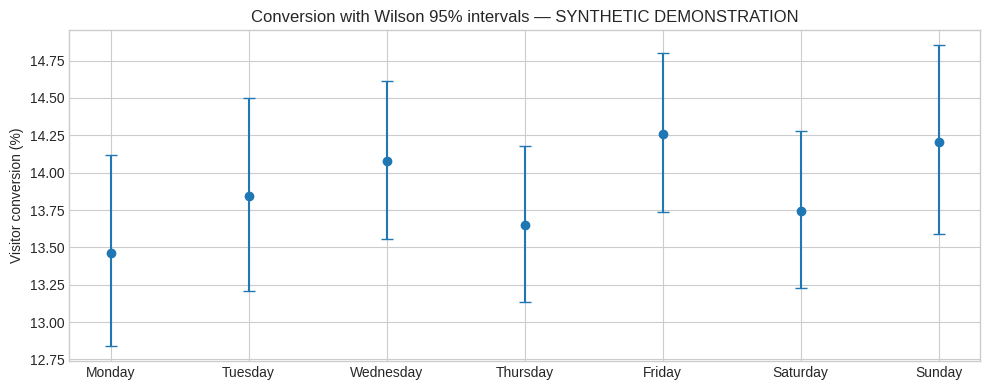

In [6]:
eligible_order = Window.partitionBy("user_id").orderBy(
    F.xxhash64("session_id", F.lit(42)), "session_id"
)
sampled_eligible = (
    analysis.filter(F.col("viewed") == 1)
    .withColumn("eligible_number", F.row_number().over(eligible_order))
    .filter(F.col("eligible_number") == 1)
)
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
observed_days = (
    sampled_eligible.groupBy("weekday_index")
    .agg(
        F.count("*").alias("visitors"),
        F.sum("converted").alias("converted_visitors"),
    )
    .toPandas()
    .set_index("weekday_index")
)
cohort_days = observed_days.reindex(range(7), fill_value=0).reset_index()
cohort_days["day"] = DAY_NAMES
cohort_days["visitors"] = cohort_days.visitors.astype(int)
cohort_days["converted_visitors"] = cohort_days.converted_visitors.astype(int)
cohort_days["conversion_rate"] = [
    rate(k, n) for k, n in zip(cohort_days.converted_visitors, cohort_days.visitors)
]
intervals = [
    conversion_interval(int(k), int(n))
    for k, n in zip(cohort_days.converted_visitors, cohort_days.visitors)
]
cohort_days[["ci_low", "ci_high"]] = pd.DataFrame(intervals, index=cohort_days.index)
display(Markdown(f"### Sampled-eligible-session visitor cohort — {DATA_LABEL}"))
display(
    cohort_days[["day", "visitors", "converted_visitors", "conversion_rate", "ci_low", "ci_high"]]
)
plottable = cohort_days[cohort_days.visitors > 0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(
    plottable.day,
    plottable.conversion_rate * 100,
    yerr=np.array(
        [
            plottable.conversion_rate - plottable.ci_low,
            plottable.ci_high - plottable.conversion_rate,
        ]
    )
    * 100,
    fmt="o",
    capsize=4,
)
ax.set(
    ylabel="Visitor conversion (%)", title=f"Conversion with Wilson 95% intervals — {DATA_LABEL}"
)
plt.tight_layout()
plt.show()

In [7]:
weekday = cohort_days.loc[cohort_days.weekday_index < 5, ["visitors", "converted_visitors"]].sum()
weekend = cohort_days.loc[cohort_days.weekday_index >= 5, ["visitors", "converted_visitors"]].sum()
primary = compare_conversion_groups(
    int(weekday.converted_visitors),
    int(weekday.visitors),
    int(weekend.converted_visitors),
    int(weekend.visitors),
)
primary_report = pd.DataFrame(
    [
        {
            **primary,
            "group_a": "Weekday",
            "group_b": "Weekend",
            "visitors_a": int(weekday.visitors),
            "visitors_b": int(weekend.visitors),
        }
    ]
)
display(primary_report)
if primary["status"] == "tested":
    decision = (
        "reject equal conversion" if primary["p_value"] < 0.05 else "do not reject equal conversion"
    )
    display(
        Markdown(
            f"**{DATA_LABEL}:** {primary['method']}, two-sided p = {primary['p_value']:.4g}; "
            f"{decision} at α = 0.05. Weekend minus weekday difference: "
            f"**{primary['difference'] * 100:.2f} percentage points**, "
            f"95% interval [{primary['ci_low'] * 100:.2f}, {primary['ci_high'] * 100:.2f}]. "
            "A nonsignificant result is not evidence of equivalence; "
            "a significant result does not prove causation."
        )
    )
else:
    display(Markdown("**Primary test unrun:** one timing group has no eligible visitors."))

,status,method,p_value,rate_a,rate_b,difference,ci_low,ci_high,group_a,group_b,visitors_a,visitors_b
0,tested,Pearson chi-square,0.8503,0.1389,0.1394,0.0005,-0.0043,0.0053,Weekday,Weekend,71780,28220


**SYNTHETIC DEMONSTRATION:** Pearson chi-square, two-sided p = 0.8503; do not reject equal conversion at α = 0.05. Weekend minus weekday difference: **0.05 percentage points**, 95% interval [-0.43, 0.53]. A nonsignificant result is not evidence of equivalence; a significant result does not prove causation.

In [8]:
monday = cohort_days.iloc[0]
comparisons = []
for _, day in cohort_days.iloc[1:].iterrows():
    result = compare_conversion_groups(
        int(monday.converted_visitors),
        int(monday.visitors),
        int(day.converted_visitors),
        int(day.visitors),
    )
    comparisons.append({"comparison": f"{day.day} minus Monday", **result})
exploratory = pd.DataFrame(comparisons)
planned_p_values = exploratory.p_value.fillna(1.0).to_numpy()
_, adjusted, _, _ = multipletests(planned_p_values, alpha=0.05, method="holm")
exploratory["holm_p_value"] = np.where(exploratory.status == "tested", adjusted, np.nan)
exploratory["reject_after_holm"] = (exploratory.status == "tested") & (adjusted < 0.05)
display(
    exploratory[
        [
            "comparison",
            "status",
            "method",
            "difference",
            "p_value",
            "holm_p_value",
            "reject_after_holm",
        ]
    ]
)

,comparison,status,method,difference,p_value,holm_p_value,reject_after_holm
0,Tuesday minus Monday,tested,Pearson chi-square,0.0038,0.4170,1.0000,False
1,Wednesday minus Monday,tested,Pearson chi-square,0.0061,0.1494,0.5978,False
2,Thursday minus Monday,tested,Pearson chi-square,0.0018,0.6634,1.0000,False
3,Friday minus Monday,tested,Pearson chi-square,0.0079,0.0622,0.3732,False
4,Saturday minus Monday,tested,Pearson chi-square,0.0028,0.5075,1.0000,False
5,Sunday minus Monday,tested,Pearson chi-square,0.0074,0.1059,0.5294,False


## Findings, interpretation, and next decisions

Interpret rates alongside eligible counts, effect sizes, and uncertainty. The following summary
is calculated from the active source. On synthetic data it is a demonstration only.
Large drop-off does not identify the reason; an unobserved offline purchase, tracking omissions,
or purchase outside the 30-minute session can also explain a lost funnel journey.

In [9]:
eligible_transitions = dropoff[dropoff.eligible_sessions > 0]
if not eligible_transitions.empty:
    largest_loss = eligible_transitions.sort_values("lost_sessions", ascending=False).iloc[0]
    display(
        Markdown(
            f"**{DATA_LABEL} findings:** Ordered conversion is "
            f"{rate(summary['converted'], summary['viewed']):.2%}. The largest absolute funnel "
            f"loss is **{largest_loss.transition}**, with {int(largest_loss.lost_sessions):,} "
            f"sessions lost ({largest_loss.dropoff_rate:.2%} of that stage's eligible sessions)."
        )
    )
if not product_pd.empty:
    highest_loss = product_pd.iloc[0]
    display(
        Markdown(
            f"Within products meeting the {MIN_PRODUCT_VIEWS}-view threshold, product "
            f"**{highest_loss.product_id}** has the largest cart-loss volume "
            f"({int(highest_loss.abandoned_sessions):,} session/product pairs). "
            "Check tracking and product context before treating this ranking as a product defect."
        )
    )
display(
    Markdown(
        "**Next steps:** inspect tracking coverage and the highest-volume lost journeys; compare "
        "visitor and product mix across calendar segments; choose a minimum worthwhile conversion "
        "change and perform sample-size planning before a randomized experiment. Use a separate "
        "holdout period to assess patterns selected from these exploratory analyses."
    )
)

**SYNTHETIC DEMONSTRATION findings:** Ordered conversion is 14.02%. The largest absolute funnel loss is **View → cart**, with 1,175,212 sessions lost (64.91% of that stage's eligible sessions).

Within products meeting the 30-view threshold, product **4698** has the largest cart-loss volume (109 session/product pairs). Check tracking and product context before treating this ranking as a product defect.

**Next steps:** inspect tracking coverage and the highest-volume lost journeys; compare visitor and product mix across calendar segments; choose a minimum worthwhile conversion change and perform sample-size planning before a randomized experiment. Use a separate holdout period to assess patterns selected from these exploratory analyses.

## Scope and reproducibility

This is observational analysis, not a randomized A/B test. No intervention or experiment
assignment is present in Retailrocket events. The sampled session represents observed eligible visits, not a visitor lifetime; conversion after a session boundary is not attributed to that session.
Product-level and behavioural segment rankings are descriptive and are not significance tests.
Missing-day cohorts produce unrun comparisons. The synthetic generator's temporal scheduling
is artificial, so a statistically significant synthetic timing result has no business meaning.

Re-run the complete notebook after changing its source. Never combine outputs from different
sources, and do not use retained synthetic outputs as evidence of real Retailrocket insights.
The final cell releases cached data and stops the Spark session started by this notebook.

In [10]:
analysis.unpersist()
spark.stop()